# 0. Packages

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

# 1. Собираем данные по RUONIA

In [3]:
(
    pd.read_excel('../data/raw/RC_F01_01_2017_T01_01_2022.xlsx')
    [['DT', 'ruo']]
    .rename(columns={"DT": "dt", "ruo": "ruonia"})
    .assign(
        ruonia=lambda x: x['ruonia'] / 100
    )
    .to_csv("../data/prepared/ruonia.csv", index=False)
)

ruonia = pd.read_csv("../data/prepared/ruonia.csv")
ruonia['dt'] = pd.to_datetime(ruonia['dt'])

print("max_dt: ", ruonia.dt.max())
print("min_dt: ", ruonia.dt.min())

ruonia.head()

max_dt:  2021-12-29 00:00:00
min_dt:  2017-01-09 00:00:00


/Users/alfa/Desktop/workspace/hse/stochastic_fx_pricing/.venv/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,dt,ruonia
0,2021-12-29,0.0813
1,2021-12-28,0.0829
2,2021-12-27,0.0815
3,2021-12-24,0.0801
4,2021-12-23,0.0777


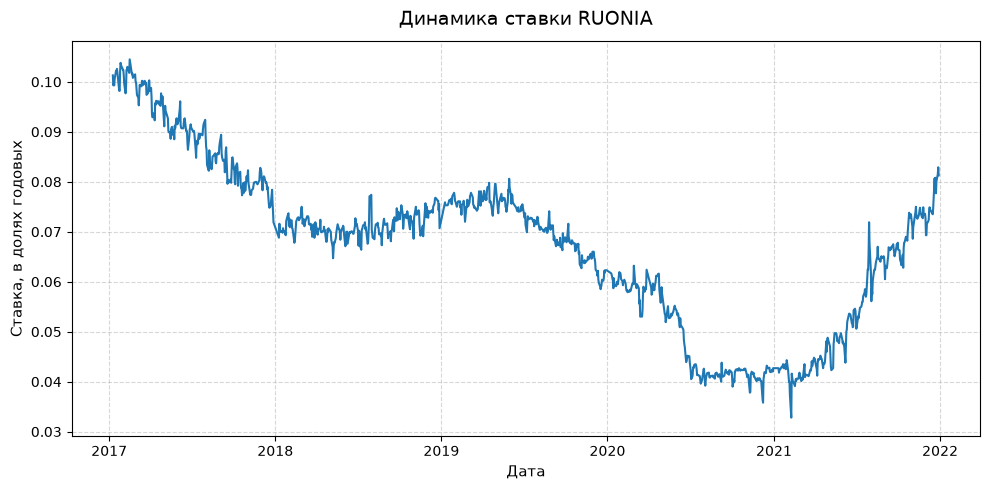

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=ruonia, x='dt', y='ruonia', ax=ax)
locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)
ax.set_title('Динамика ставки RUONIA', fontsize=14, pad=12)
ax.set_xlabel('Дата', fontsize=11)
ax.set_ylabel('Ставка, в долях годовых', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 2. Собираем данные по EFFR

In [5]:
(
    pd.read_csv('../data/raw/EFFR.csv')
    .rename(columns={"observation_date": "dt", "EFFR": "effr"})
    .assign(
        effr=lambda x: x['effr'] / 100 
    )
    .to_csv("../data/prepared/effr.csv", index=False)
)

effr = pd.read_csv("../data/prepared/effr.csv")
effr['dt'] = pd.to_datetime(effr['dt'])

print("max_dt: ", effr.dt.max())
print("min_dt: ", effr.dt.min())

effr.head()

max_dt:  2021-12-31 00:00:00
min_dt:  2017-01-03 00:00:00


,dt,effr
0,2017-01-03,0.0066
1,2017-01-04,0.0066
2,2017-01-05,0.0066
3,2017-01-06,0.0066
4,2017-01-09,0.0066


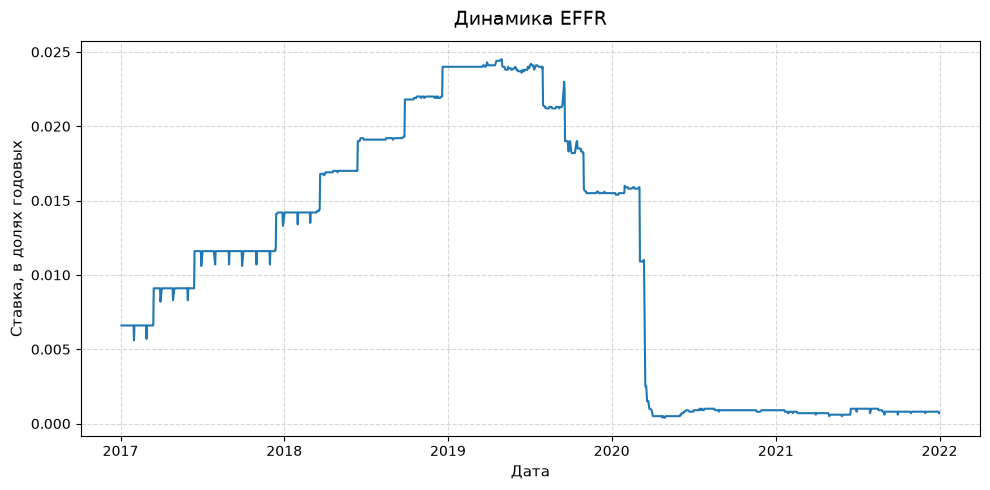

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=effr, x='dt', y='effr', ax=ax)
locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)
ax.set_title('Динамика EFFR', fontsize=14, pad=12)
ax.set_xlabel('Дата', fontsize=11)
ax.set_ylabel('Ставка, в долях годовых', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 3. Собираем данные по обменному курсу USD/RUB

In [7]:
(
    pd.concat([
        pd.read_csv('../data/raw/USD000UTSTOM_170101_181231.csv', delimiter=';', decimal='.'),
        pd.read_csv('../data/raw/USD000UTSTOM_190101_220101.csv', delimiter=';', decimal='.'),
    ])
    [['<DATE>', '<CLOSE>']]
    .rename(columns={"<DATE>": "dt", "<CLOSE>": "fx"})
    .assign(
        dt=lambda x: pd.to_datetime(x['dt'], format="%Y%m%d")
    )
    .to_csv("../data/prepared/fx.csv", index=False)
)

fx = pd.read_csv("../data/prepared/fx.csv")
fx['dt'] = pd.to_datetime(fx['dt'])

print("max_dt: ", fx.dt.max())
print("min_dt: ", fx.dt.min())

fx.head()

max_dt:  2021-12-30 00:00:00
min_dt:  2017-01-03 00:00:00


/var/folders/f6/hwzbqsn10fn6p6gx8d5vmnfm0000gn/T/ipykernel_4667/1316252233.py:9: Pandas4Warning: Parsing integer or float values with a format in to_datetime is deprecated. In a future version these will be interpreted as epochs via the 'unit' keyword instead. Cast them to strings first to retain the current behavior.
  dt=lambda x: pd.to_datetime(x['dt'], format="%Y%m%d")


,dt,fx
0,2017-01-03,60.9025
1,2017-01-04,60.4600
2,2017-01-05,59.4500
3,2017-01-06,59.6200
4,2017-01-09,60.0900


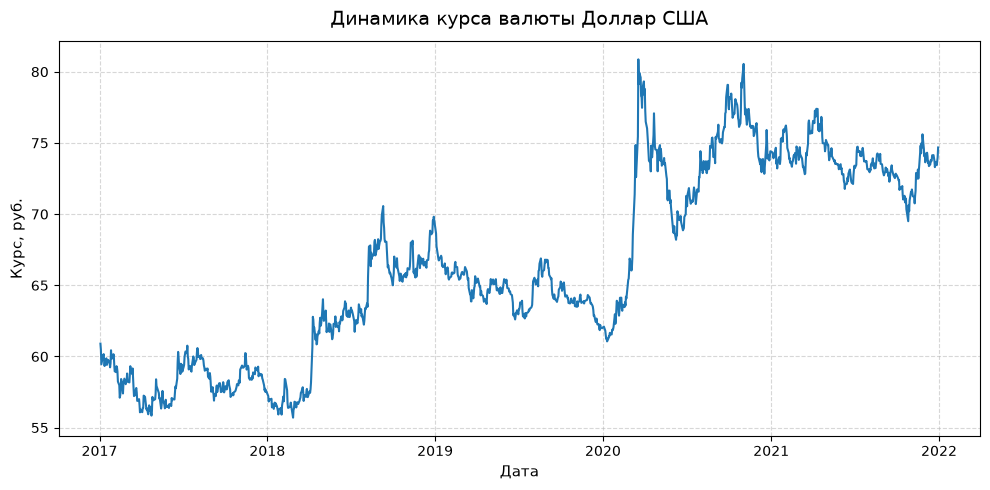

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=fx, x='dt', y='fx', ax=ax)
locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)
ax.set_title('Динамика курса валюты Доллар США', fontsize=14, pad=12)
ax.set_xlabel('Дата', fontsize=11)
ax.set_ylabel('Курс, руб.', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()